# II (suite). Le niveau de vie le long des lignes


Nous changeons d'indicateur et d'échelle : le **niveau de vie** (Filosofi), mesuré sur des **carreaux de 200 m**, permet de suivre les contrastes station par station, et pas seulement commune par commune. Trois étapes :

- **II.2 Les montagnes** : le niveau de vie le long de quelques lignes, en commençant par le RER B ;
- **II.3 Le relief** : Paris en 3D, avec les lignes de métro ;
- **II.4 L'hétérogénéité des lignes** : toutes les lignes comparées, pour savoir si les écarts tiennent à la limite de Paris, et si des banlieues riches font exception.

Le notebook réutilise les fonctions des modules du projet (`pretraitement_donnees.py`, `analyse_donnees.py`, `visualisation_donnees.py`).

In [ ]:
import matplotlib.pyplot as plt

from analyse_donnees import (
    ajouter_communes_stations,
    calculer_carreaux_traverses,
    calculer_profils_zones,
    calculer_nv_par_commune,
    calculer_nv_par_station,
    calculer_temps_trajet,
    classer_carreaux_zones,
    construire_grille_nv,
    joindre_carreaux_stations,
    mesurer_heterogeneite_lignes,
    positionner_stations_ligne,
)
from pretraitement_donnees import (
    URL_ZIP_FILOSOFI,
    URL_ZIP_IDFM,
    charger_arrets,
    charger_communes,
    charger_filosofi,
    charger_horaires,
    charger_parcours,
    charger_routes,
    charger_stations,
    charger_trips,
    construire_aretes,
    construire_centres_carreaux,
    construire_graphe_reseau,
    construire_lignes_idfm,
    construire_stations,
    indicateurs_filosofi,
    telecharger_zip,
)
from visualisation_donnees import (
    ajouter_selecteur_lignes,
    enregistrer_graphique,
    generer_carte_communes_riches,
    generer_halteres_paris_banlieue,
    generer_montagnes_par_ligne,
    generer_relief_3d,
)

## Préparation des données

Les données (environ 3,4 Go une fois décompressées) ne sont téléchargées qu'une fois : décommenter les deux lignes ci-dessous au premier lancement.

In [ ]:
# telecharger_zip(URL_ZIP_IDFM, "idfm")
# telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")

### Niveau de vie : Filosofi

Les carreaux de 200 m de l'Insee donnent, pour chaque carreau habité, le nombre d'habitants (`ind`) et la somme de leurs niveaux de vie (`ind_snv`). Nous en déduisons le niveau de vie moyen `nv` de chaque carreau.

In [ ]:
df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)
gpd_centres = construire_centres_carreaux(df_filosofi)

### Réseau : IDFM

Nous gardons les lignes de métro et de RER, leurs tracés et leurs stations.

In [ ]:
# Métro et RER seulement (charger_routes ajoute sinon le tram et le Transilien)
df_routes = charger_routes("data/idfm", modes=("metro", "rer"))
df_trips = charger_trips("data/idfm", df_routes)
gpd_idfm = construire_lignes_idfm(charger_parcours("data/idfm", df_trips))

df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)
gpd_stations = construire_stations(df_stations)

TypeError: charger_routes() got an unexpected keyword argument 'modes'

### Rattachement des carreaux aux stations

Chaque carreau est rattaché à sa station la plus proche (à moins de 1,5 km). Le calcul des temps de trajet vers Châtelet et La Défense fait partie de ce rattachement, même si les montagnes ne l'utilisent pas.

In [ ]:
df_horaires = charger_horaires("data/idfm", df_trips)
graphe_reseau = construire_graphe_reseau(construire_aretes(df_horaires))
destinations = gpd_stations.loc[
    gpd_stations["stop_name"].isin(["Châtelet - Les Halles", "Châtelet", "La Défense"]),
    "stop_id",
]
df_temps = calculer_temps_trajet(graphe_reseau, destinations)

gpd_carreaux = joindre_carreaux_stations(
    gpd_centres, gpd_stations, df_temps, distance_max=1500, vitesse_marche=75
)

### Indicateurs

- **Autour de chaque station** : niveau de vie moyen des habitants dont c'est la station la plus proche.
- **Par commune** (ou par arrondissement à Paris) : niveau de vie moyen de tous ses habitants.
- **Moyenne de l'Île-de-France** : la référence des montagnes.

Toutes les moyennes sont pondérées par la population (somme des niveaux de vie divisée par le nombre d'habitants), et non des moyennes de carreaux.

In [ ]:
df_nv = calculer_nv_par_station(gpd_carreaux)
nv_moyen = gpd_carreaux["ind_snv"].sum() / gpd_carreaux["ind"].sum()
gpd_communes = charger_communes()
nv_communes = calculer_nv_par_commune(gpd_centres, gpd_communes)
print(f"Niveau de vie moyen en Île-de-France : {nv_moyen:,.0f} € par an".replace(",", " "))

Niveau de vie moyen en Île-de-France : 28 543 € par an


Pour chaque ligne, nous plaçons les stations le long du tracé (en km depuis le terminus ouest, ou nord pour une ligne nord-sud), nous les rattachons à leur commune, et nous relevons tous les carreaux de 200 m que le tracé traverse.

In [ ]:
def preparer_lignes(noms):
    "Stations, couleur et carreaux traversés de chaque ligne"
    lignes = {}
    for nom in noms:
        gpd_ligne = positionner_stations_ligne(gpd_stations, df_stations, gpd_idfm, nom)
        gpd_ligne = ajouter_communes_stations(gpd_ligne, gpd_communes)
        df_carreaux = calculer_carreaux_traverses(df_filosofi, gpd_ligne, gpd_idfm, nom)
        filtre = df_routes["route_short_name"] == nom
        couleur = "#" + df_routes.loc[filtre, "route_color"].iloc[0]
        lignes[nom] = (gpd_ligne, couleur, df_carreaux)
    return lignes

### II.2 Les montagnes : le niveau de vie station par station

Une « montagne » suit une ligne d'un terminus à l'autre : plus elle monte, plus les habitants autour sont aisés. Elle permet de vérifier, station par station et avec le niveau de vie, les contrastes que la part d'ouvriers montrait commune par commune.

**Comment les lire :**

- **Barres** : un carreau de 200 m traversé par la ligne, sur la longueur de tracé qui le traverse. Elles partent de la moyenne de l'Île-de-France (pointillés) : vers le haut et en vert si le carreau est plus riche, vers le bas et en rouge s'il est plus pauvre. Les trous correspondent aux endroits sans habitants (Seine, parcs, bois, aéroports).
- **Courbe de la couleur de la ligne** : niveau de vie autour de chaque station.
- **Traits bleus** : niveau de vie moyen de la commune ou de l'arrondissement.
- **Traits noirs verticaux** : entrée ou sortie de Paris.
- **Plan** : tracé des lignes ; la pastille marque le terminus de départ (0 km).

Chaque ligne a sa figure, en deux panneaux l'un sous l'autre, alignés sur les mêmes km (chaque station est à la même place en haut et en bas) :

1. **En haut, le niveau de vie** (barres, courbe, traits bleus décrits ci-dessus).
2. **En bas, le nombre d'habitants rattachés à chaque station** : ceux dont c'est la station de métro ou de RER la plus proche, à moins de 1,5 km. La ligne pointillée est la moyenne sur toutes les stations de métro et de RER.

Ce nombre dépend de deux choses : la densité de population autour de la station, et l'écart avec les stations voisines. Dans Paris, les stations sont si proches que chacune ne récupère que quelques centaines à quelques milliers d'habitants ; en banlieue, une gare isolée en récupère des dizaines de milliers.

Les échelles verticales et les couleurs sont les mêmes pour toutes les lignes d'une même série (RER, puis métro) : leurs figures sont directement comparables.

#### RER : lignes B et A

Nous commençons par le RER B, sur lequel s'arrête le rapport : la part d'ouvriers y opposait un nord populaire, un centre parisien où ils sont rares et un sud plus aisé. Le RER A, l'autre grande traversée de la région, d'ouest en est, suit.

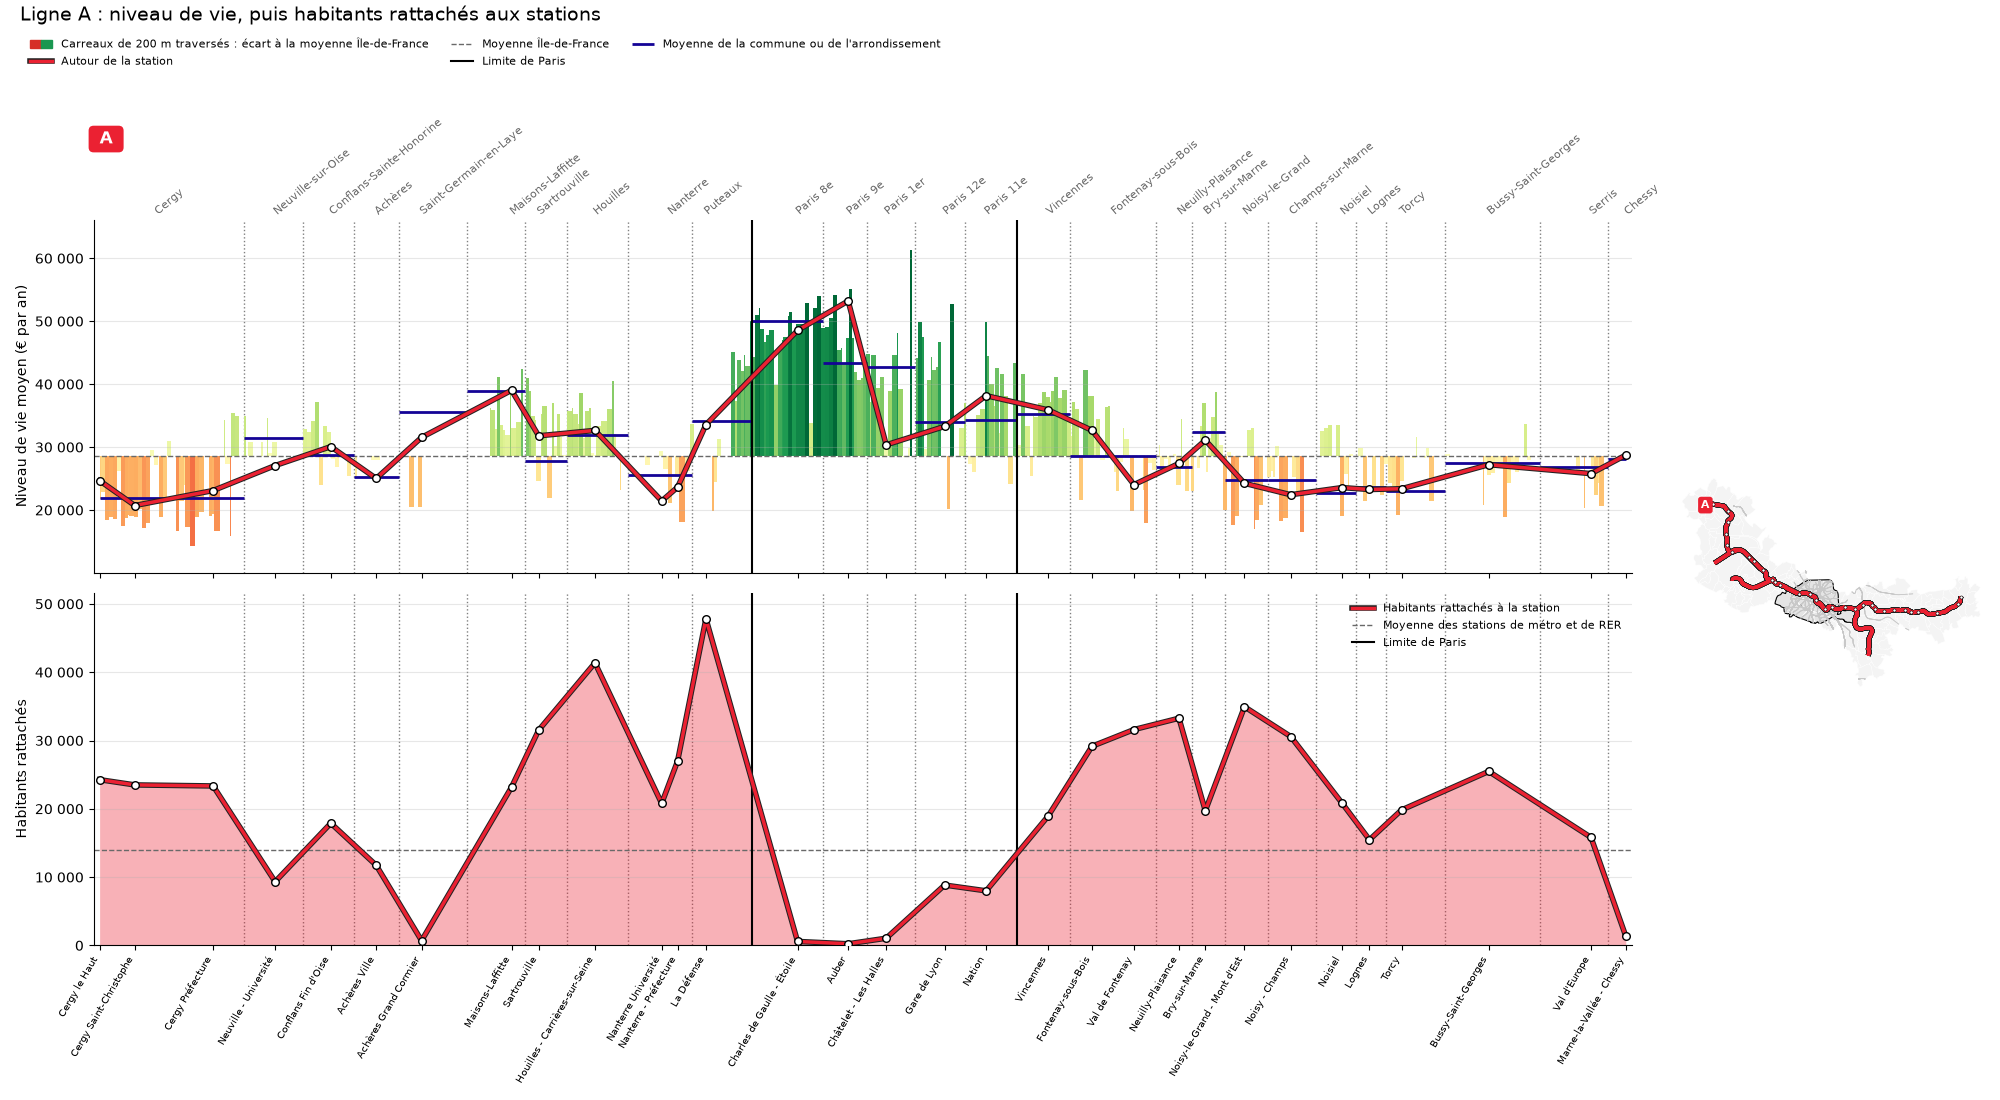

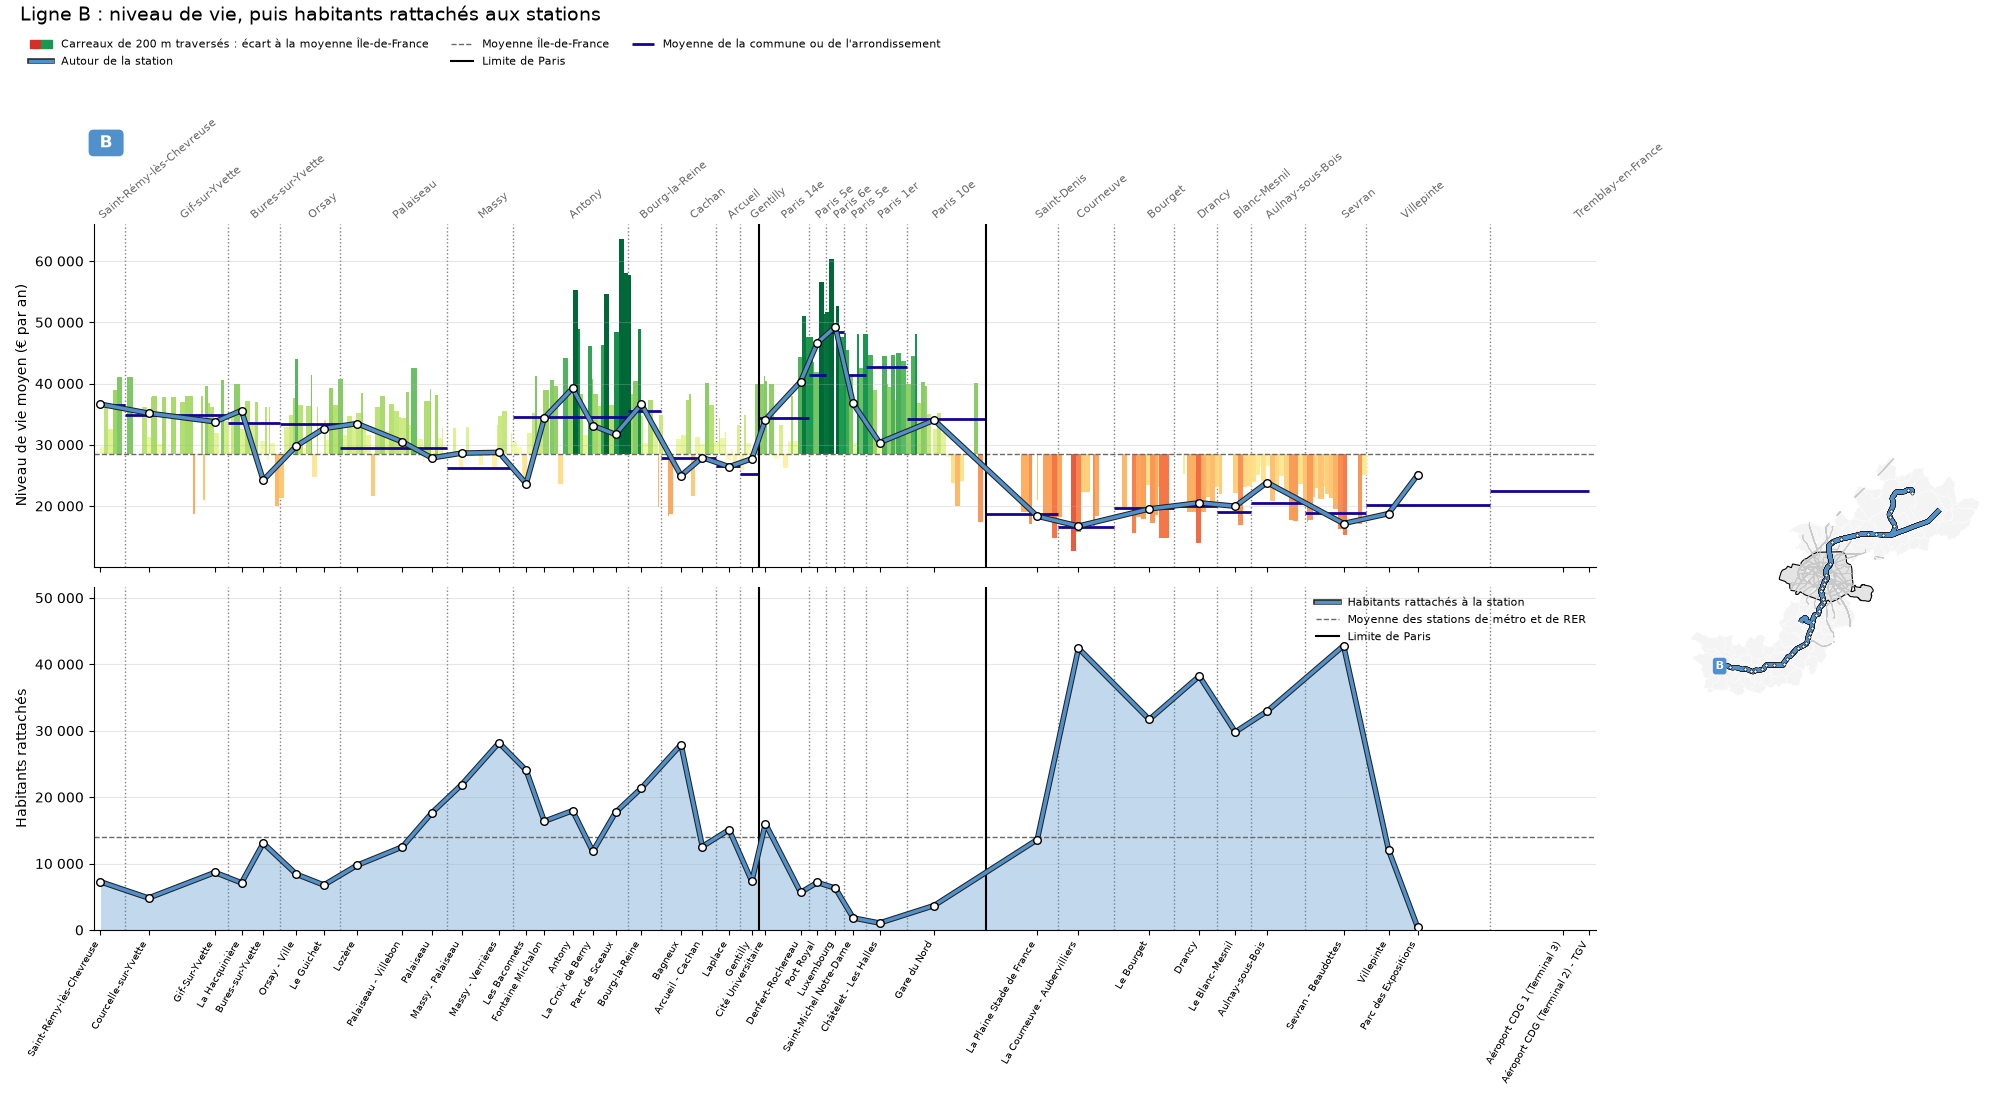

In [ ]:
lignes_rer = preparer_lignes(["B", "A"])
figures = generer_montagnes_par_ligne(
    lignes_rer, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
plt.show()

> **Lecture :** sur le RER B, entre Gare du Nord (10e arrondissement) et La Courneuve – Aubervilliers, le niveau de vie moyen autour de la station est divisé par deux : de 34 000 € à 16 700 € par an. Avec 42 400 habitants rattachés, La Courneuve – Aubervilliers en compte trois fois plus que la moyenne des stations de métro et de RER (14 000).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Métro : lignes 1, 2, 9, 11, 13 et 14

Mêmes figures pour six lignes de métro, dont la 14, dernier exemple du rapport, et la 13, la plus contrastée des lignes de métro (voir II.4).

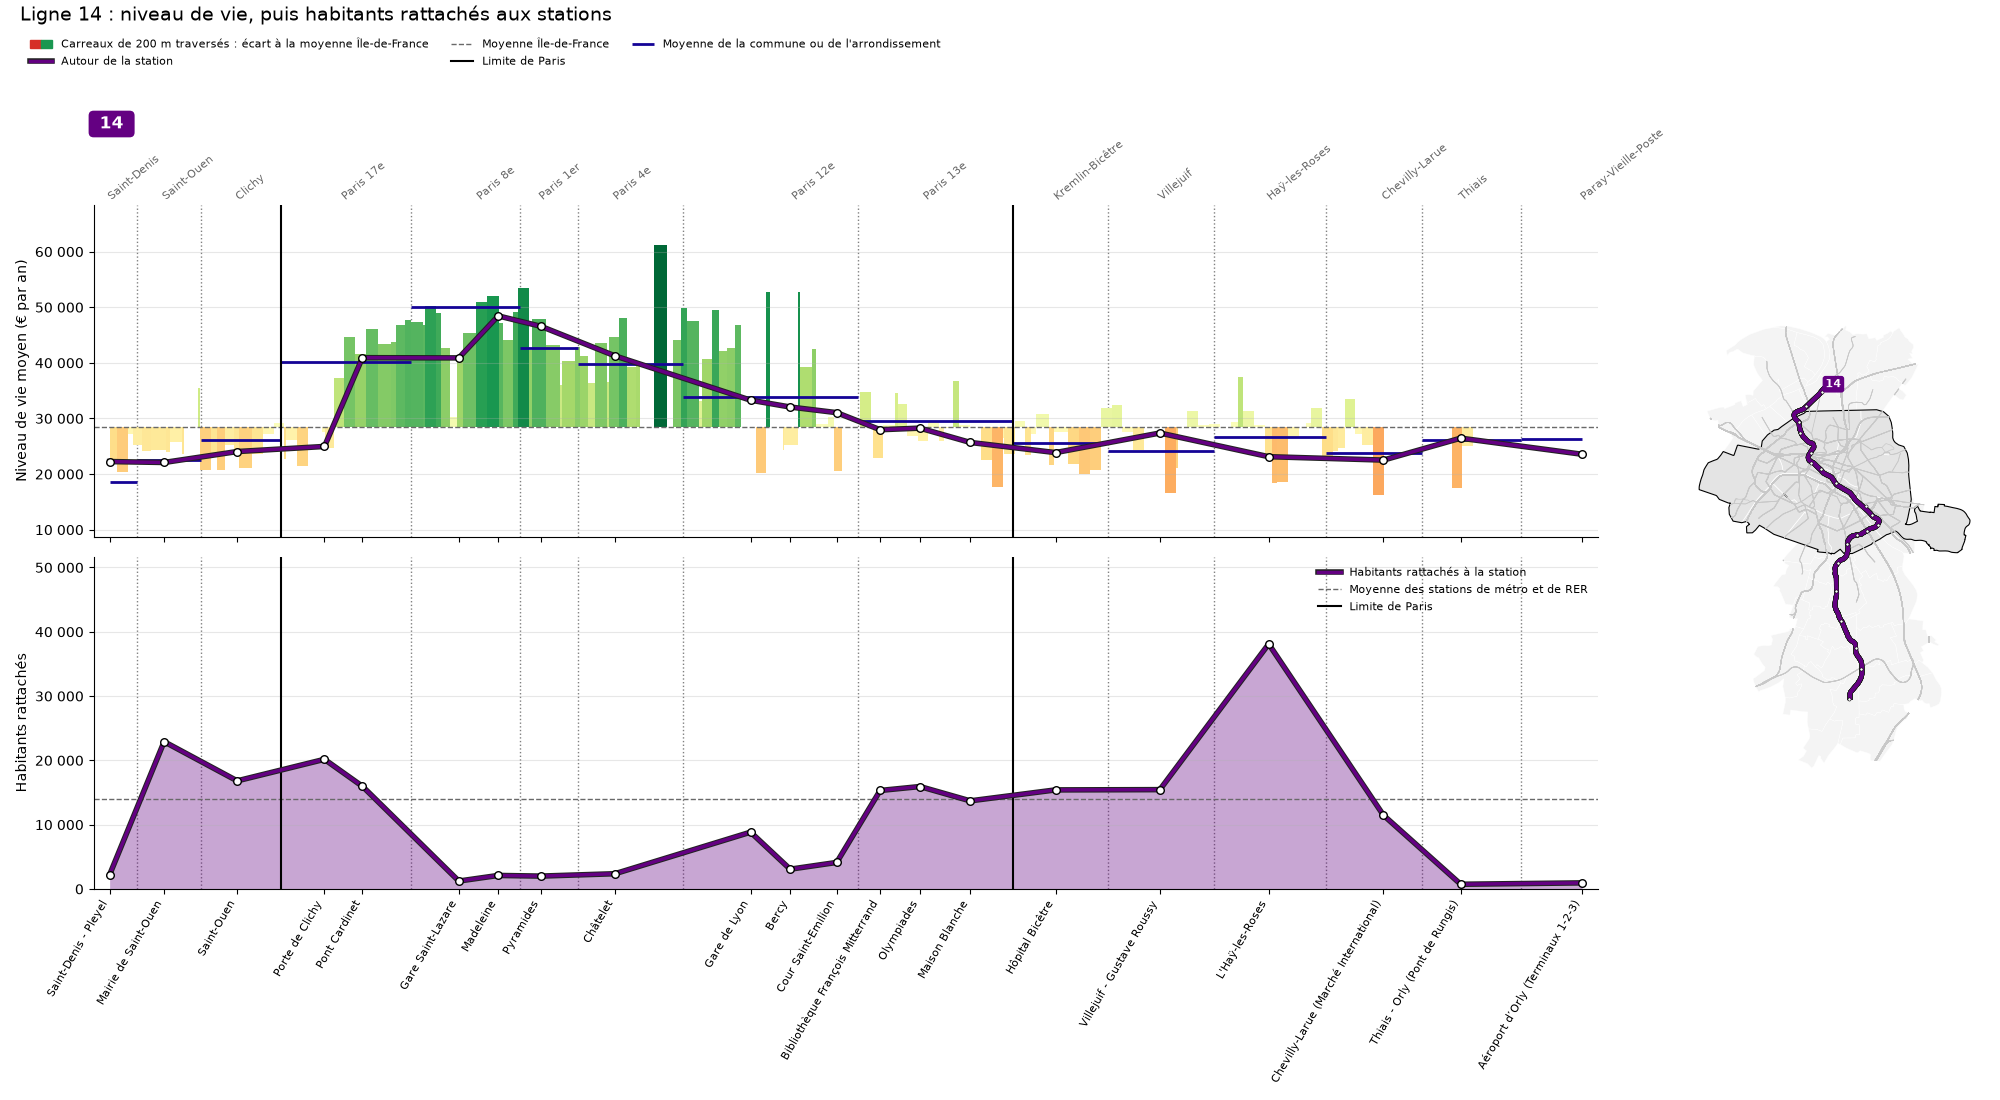

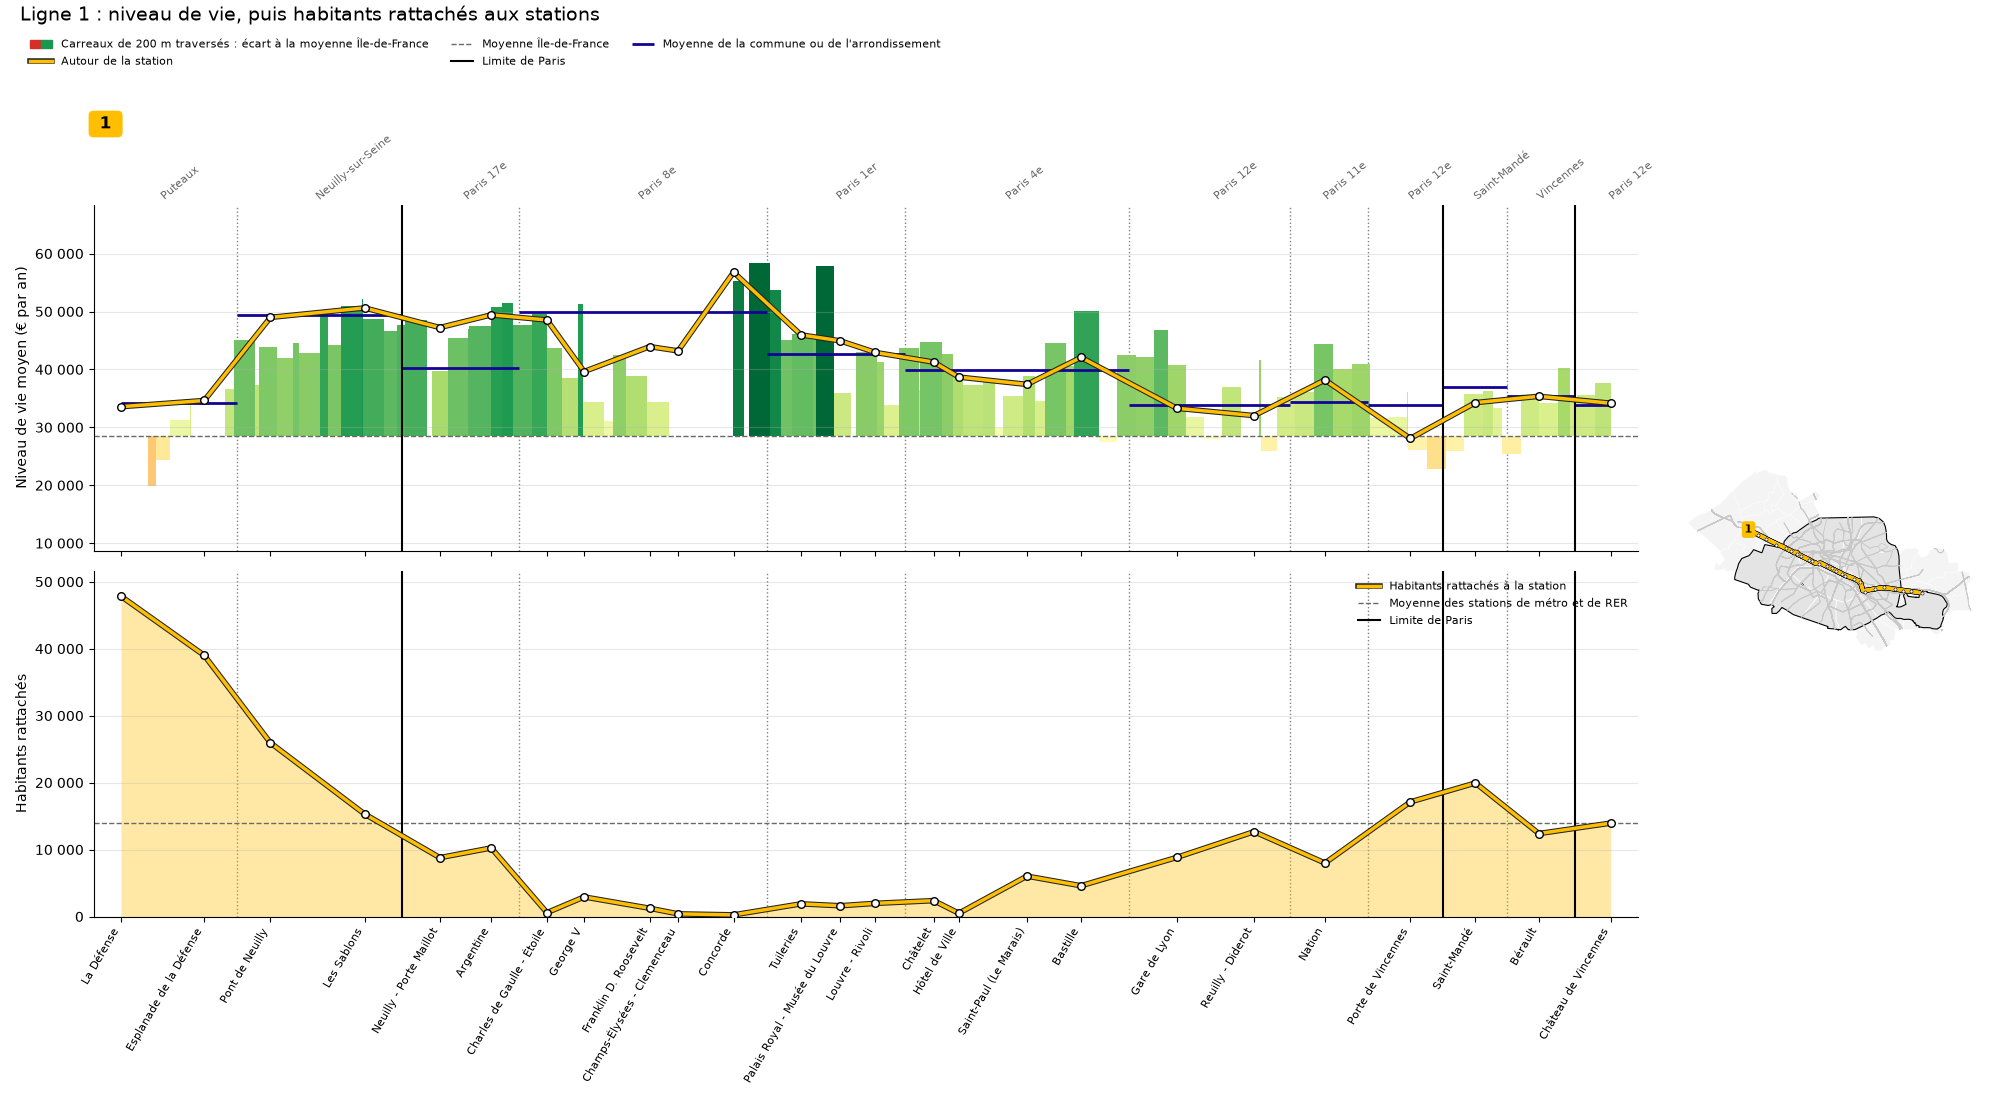

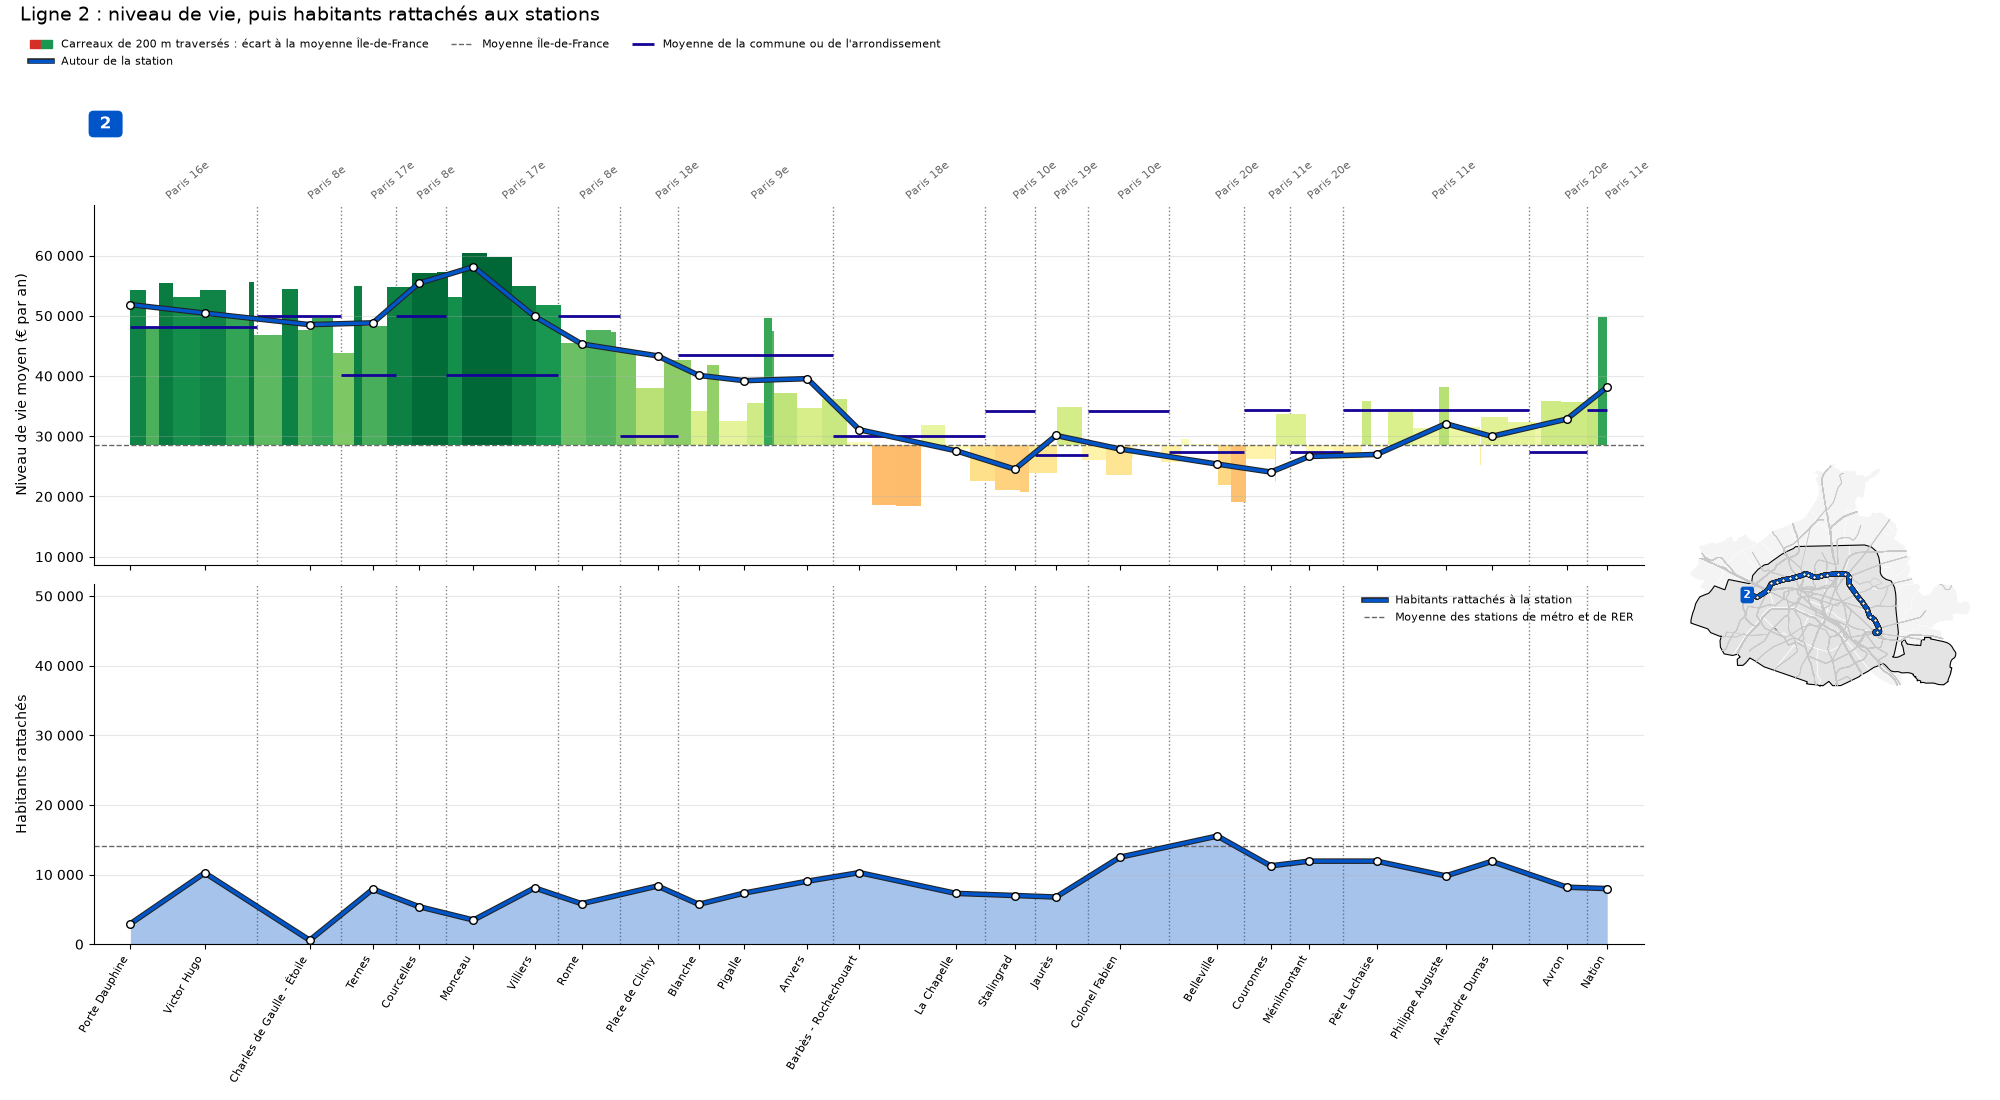

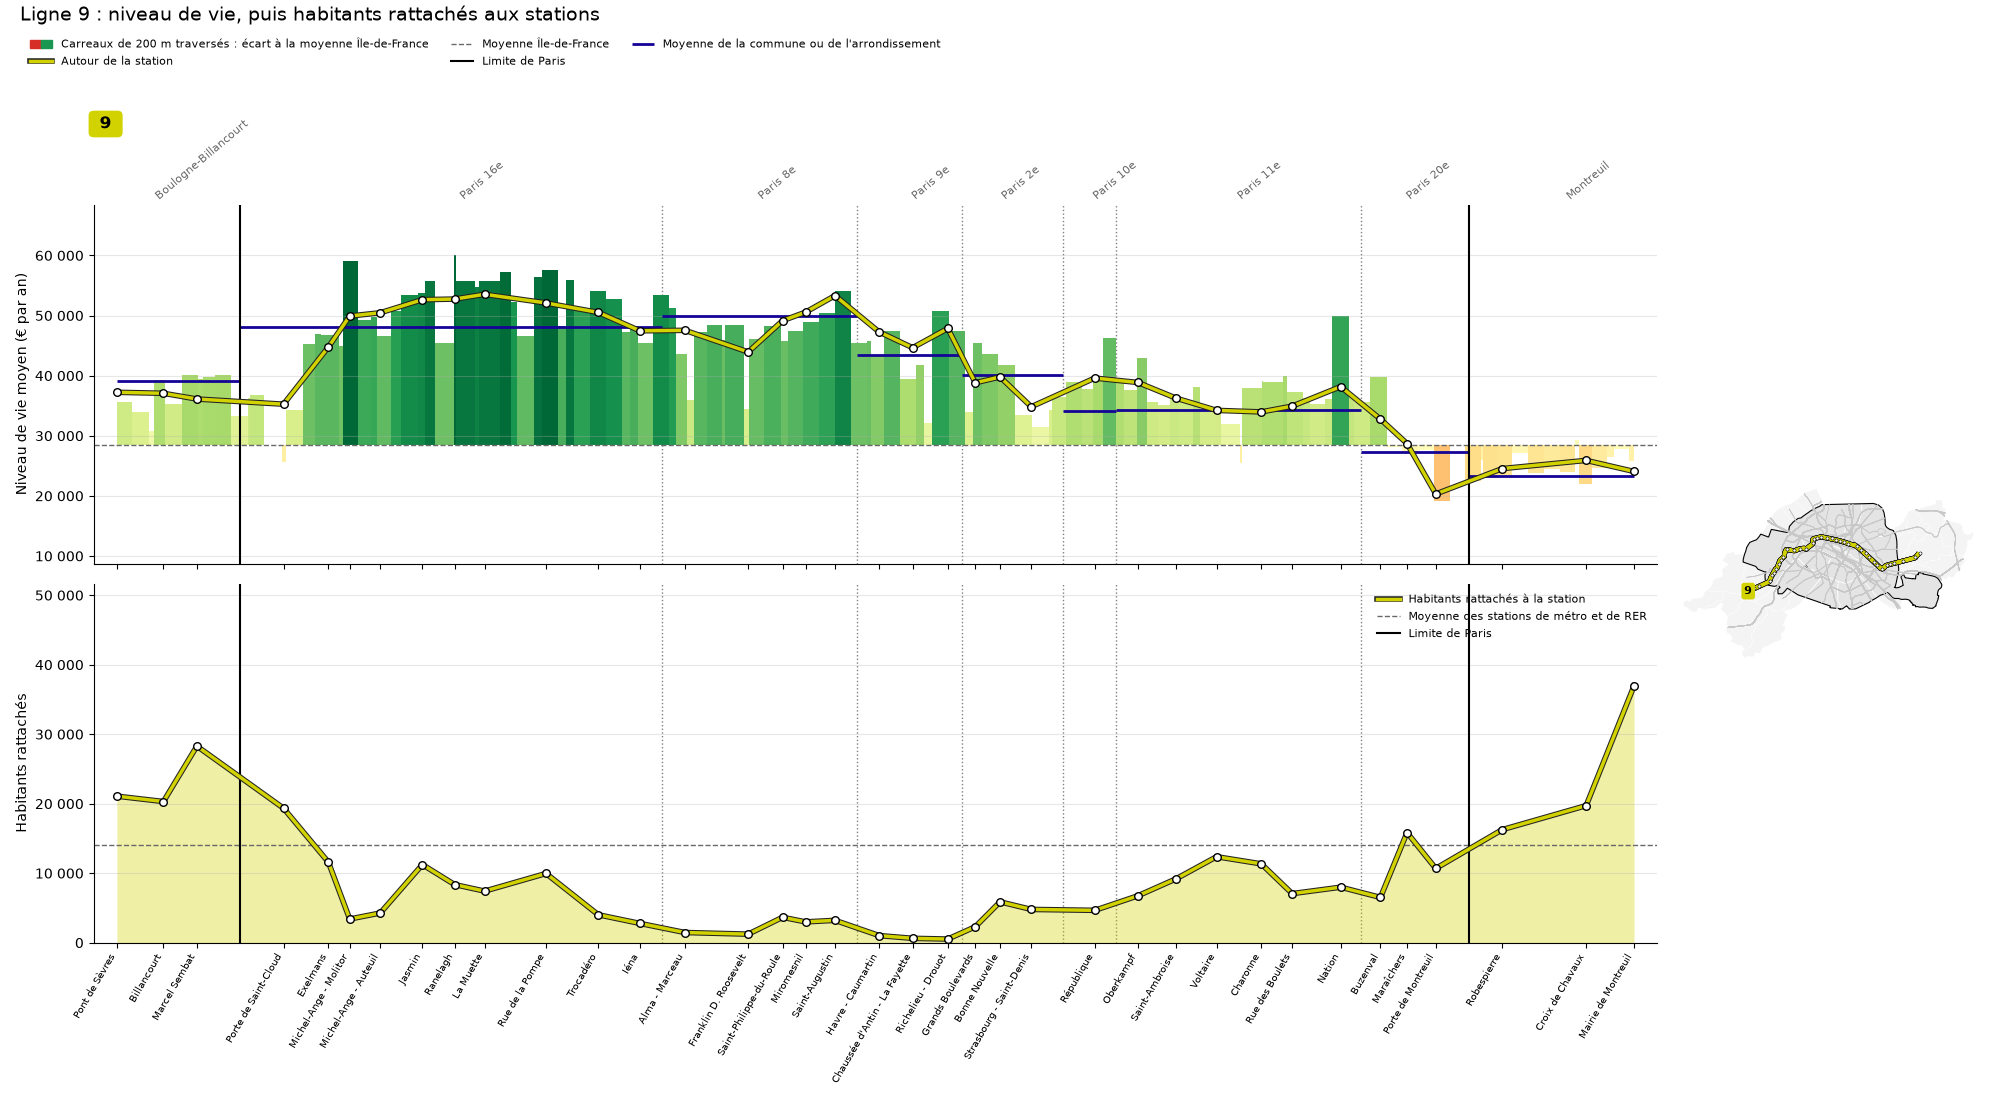

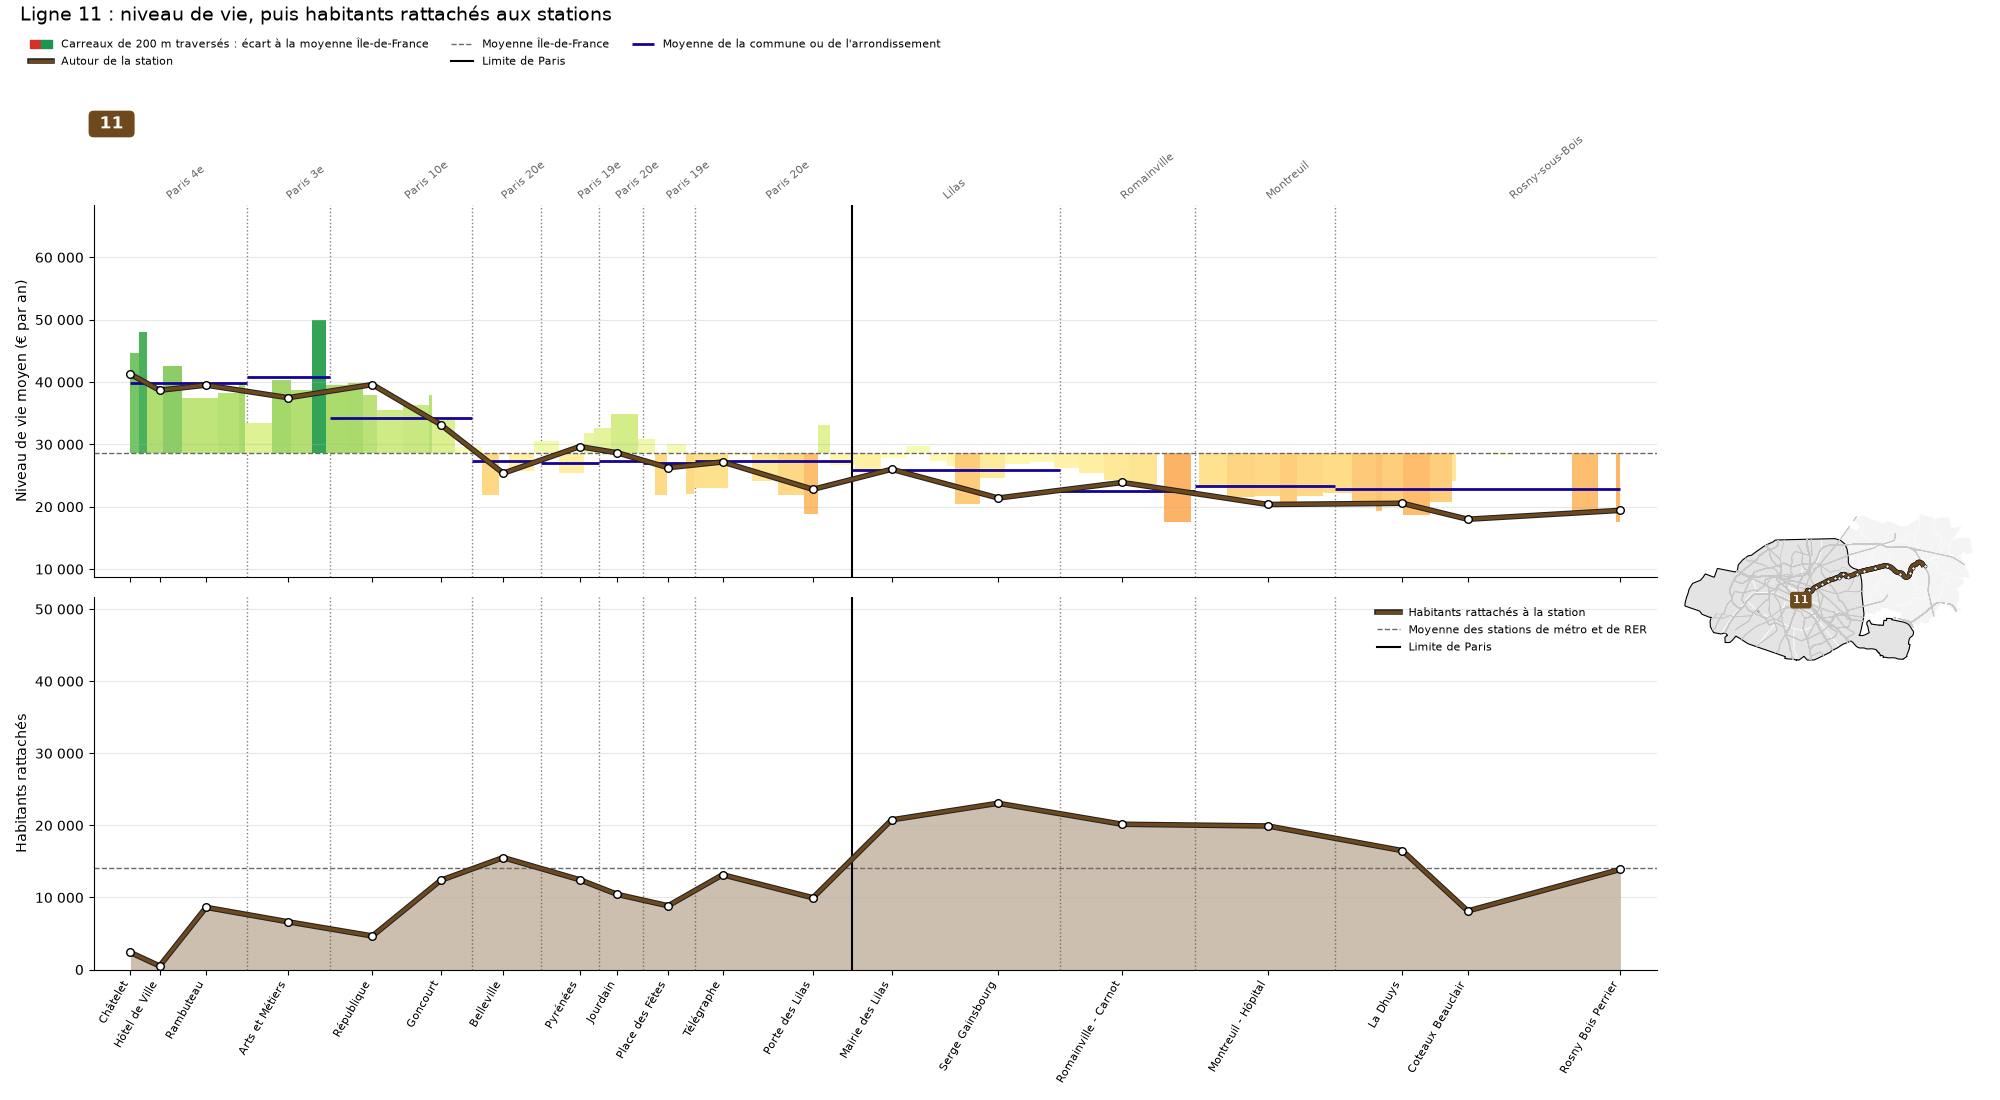

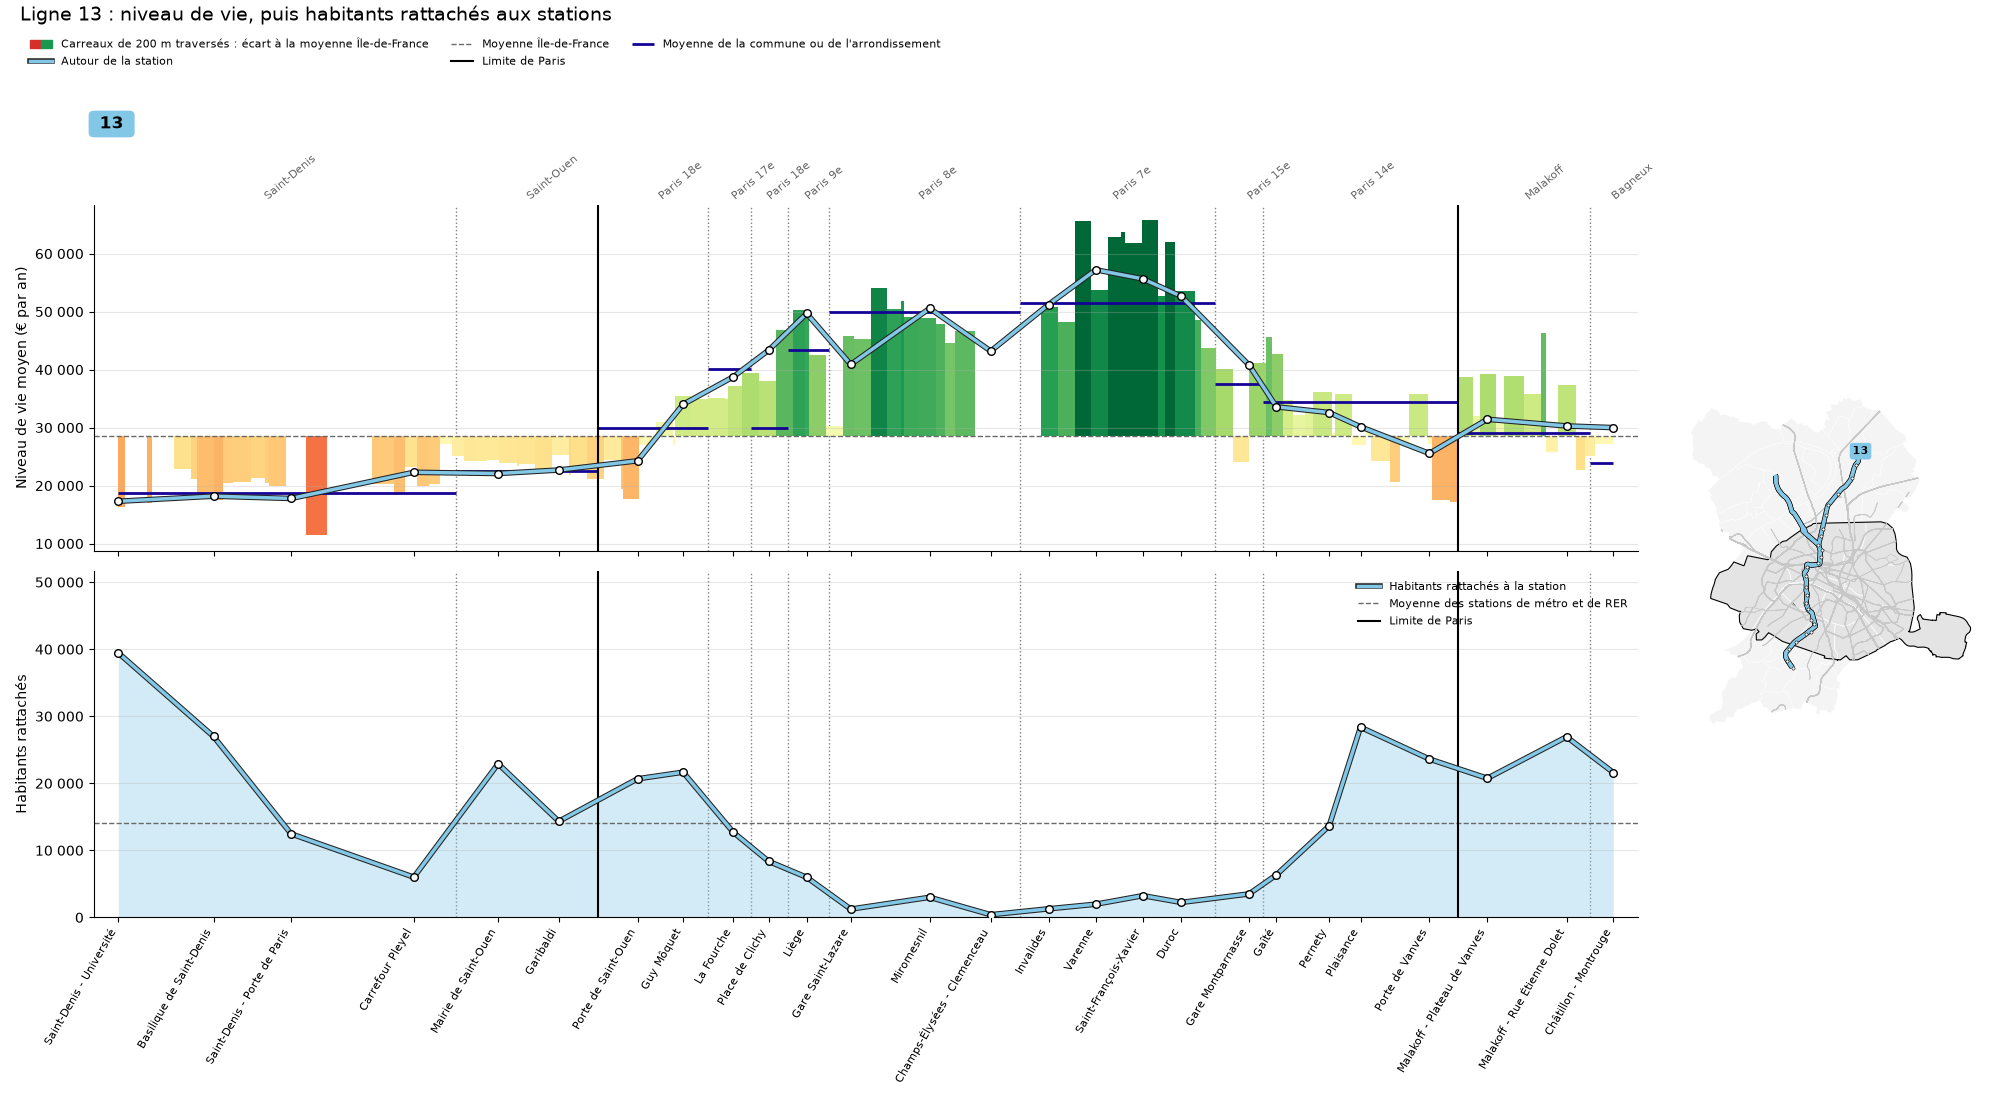

In [ ]:
lignes_metro = preparer_lignes(["1", "2", "9", "11", "13", "14"])
figures = generer_montagnes_par_ligne(
    lignes_metro, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
plt.show()

> **Lecture :** sur la ligne 13, les 39 400 habitants rattachés à la station Saint-Denis – Université ont un niveau de vie moyen de 17 300 € par an, en dessous de la moyenne de l'Île-de-France (28 500 €). 12 km plus loin, autour de Varenne (7e arrondissement), il atteint 57 200 €, soit plus de trois fois plus, mais pour moins de 2 000 habitants (panneau du bas).
>
> Sur la ligne 1, au contraire, sortir de Paris par l'ouest ne fait pas descendre la "montagne" : autour des Sablons (Neuilly-sur-Seine), le niveau de vie moyen est de 50 600 €, plus que dans toutes les stations parisiennes de la ligne sauf Concorde (qui n'a cependant que 300 habitants dans ses carreaux associés).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

### II.3 Vue d'ensemble : le relief du niveau de vie à Paris

Chaque point de la surface est le niveau de vie moyen des habitants dans un carré de 1 km de côté centré sur lui (moyenne pondérée par la population, sur la grille de 200 m de Filosofi), lissant le relief sans effacer les quartiers.

- **Couleurs** : les mêmes que les montagnes, rouge sous la moyenne de l'Île-de-France, vert au-dessus.
- **Trous** : pas d'habitants (bois de Boulogne et de Vincennes, grands parcs).



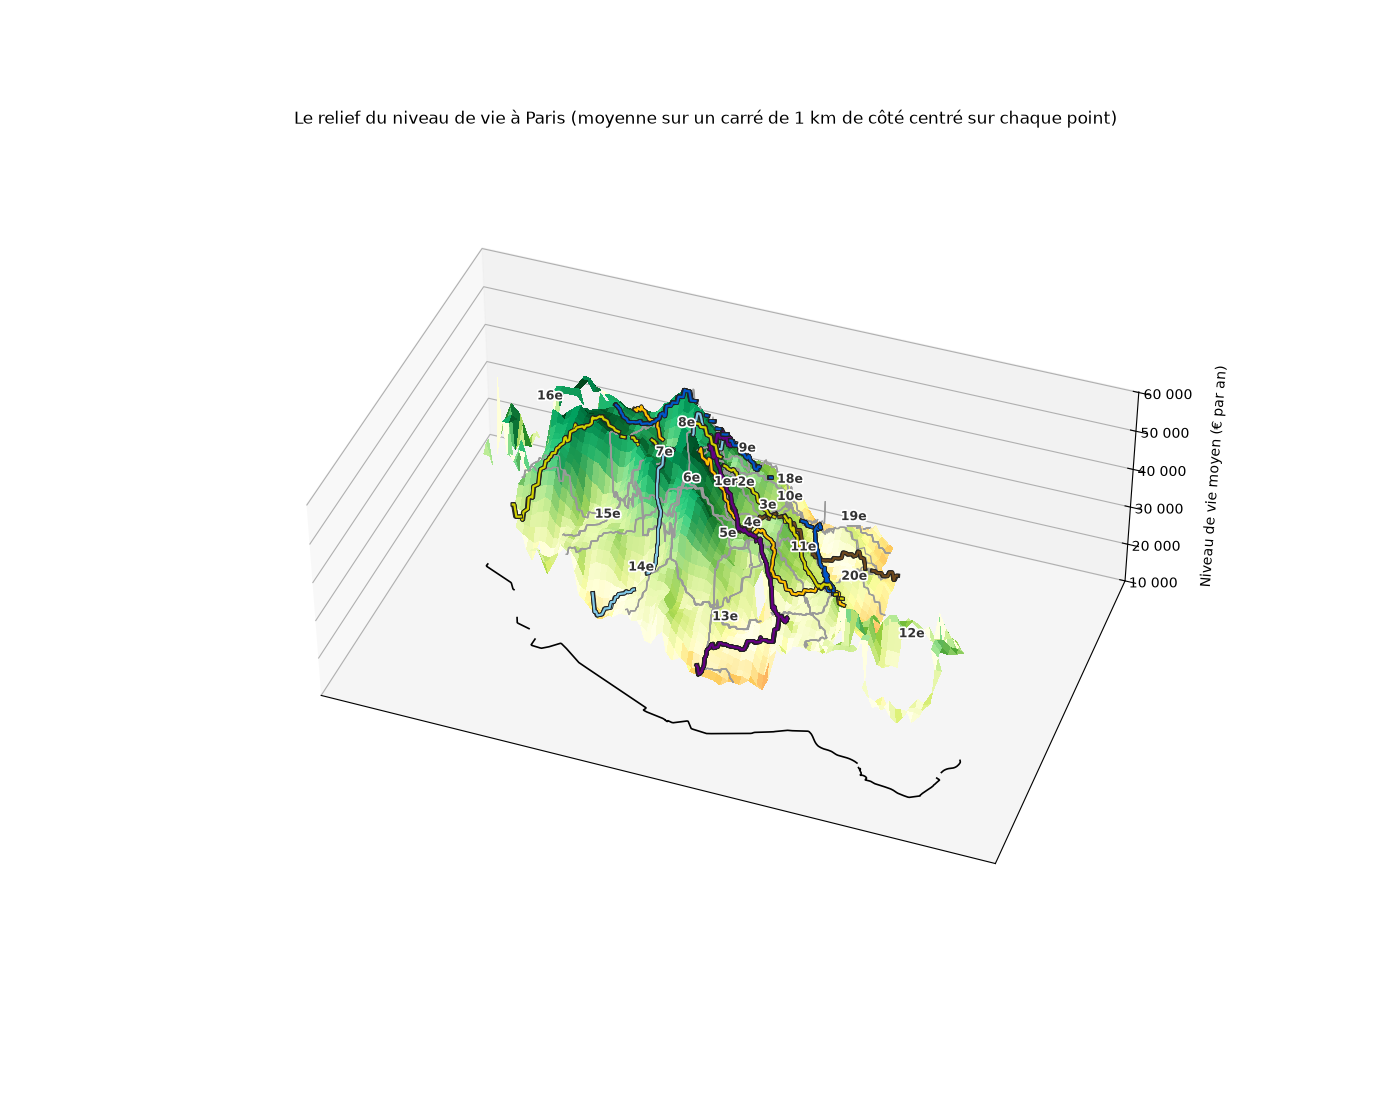

In [ ]:
# Figure interactive : clic gauche + glisser pour tourner, clic droit pour zoomer
%matplotlib widget
from IPython.display import display

gpd_paris = gpd_communes[gpd_communes["nom"].str.startswith("Paris")].to_crs(3035)
grille = construire_grille_nv(df_filosofi, gpd_paris.union_all(), rayon=2)

# Lignes mises en valeur au départ : celles des montagnes ; les autres sont en gris
selection = list(lignes_metro)
with plt.ioff():  # on affiche nous-mêmes la figure, sous les boutons
    ax, traits = generer_relief_3d(grille, nv_moyen, gpd_idfm, gpd_paris, selection)
enregistrer_graphique(ax, "Relief 3D du niveau de vie à Paris")
display(ajouter_selecteur_lignes(ax, traits, selection), ax.figure.canvas)

> **Lecture :** le point le plus haut du relief, dans le 16e arrondissement, correspond à un niveau de vie moyen de 59 100 € par an (moyenne sur un carré de 1 km de côté) ; le point le plus bas, dans le 18e, est à 16 400 €, soit 3,6 fois moins.
>
> *Champ : habitants de Paris ; points avec au moins 100 habitants dans le carré de 1 km.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

Pour filer la métaphore : les sommets, là où le niveau de vie est le plus élevé (ouest de Paris : 7e, 8e, 16e, 17e), sont aussi très bien desservis. Les lignes 2, 9 et 13 les traversent avant de redescendre vers des quartiers plus modestes. Le principal nœud du réseau, Châtelet, se trouve lui en contrebas de ces sommets.

Attention : ceci est un rendu missé et ne permet pas de visualiser les contrastes de revenus locaux (type HLM, rue de la paix etc).

### II.4 Hétérogénéité des lignes : effet Paris et banlieues riches

Les montagnes montrent que le niveau de vie change beaucoup le long de certaines lignes. Trois questions :

1. **Quelles lignes sont les plus hétérogènes ?**
2. **Est-ce seulement un effet de la limite de Paris ?** Le niveau de vie fait souvent une marche au périphérique : une ligne qui sort de Paris paraît hétérogène pour cette seule raison.
3. **Les banlieues riches cassent-elles l'opposition « Paris riche, banlieue pauvre » ?**

**Méthode**

- **Lignes** : les 16 métros et les 5 RER, limités à Paris et la petite couronne (Hauts-de-Seine, Seine-Saint-Denis, Val-de-Marne). Sans cette limite, les RER (50 à 80 km) seraient impactés par la grande couronne et pas comparables aux métros.
- **Tronçons de 500 m** le long du tracé (le plus long de chaque ligne), avec les habitants à moins de 400 m. Toutes les lignes sont mesurées avec la même règle, quel que soit l'espacement des stations : on mesure le territoire *traversé*, pas seulement celui desservi par chaque station. Les tronçons de moins de 100 habitants sont écartés.
- **Zone** : un tronçon est « Paris » si la majorité de ses habitants vit dans Paris, « banlieue » sinon.
- **Indicateurs**, sur le log du niveau de vie (les écarts se lisent en %) :
  - **volatilité** : écart-type des variations d'un tronçon au suivant, comme la volatilité d'un cours de bourse, avec « par 500 m » au lieu de « par jour » ;
  - **dispersion** : écart-type du niveau de vie sur toute la ligne, pondéré par la population ;
  - **effet Paris** : part de la variance due au seul fait d'être dans Paris ou non (variance entre les deux zones / variance totale). 60 % veut dire que 60 % des écarts le long de la ligne s'expliquent par la limite de Paris ; le reste vient des écarts à l'intérieur de Paris et à l'intérieur de la banlieue.
- **Banlieue riche** : commune de petite couronne dont le niveau de vie moyen dépasse celui de Paris. Pour chaque ligne, on donne la part de ses habitants de banlieue qui vivent dans une telle commune.

In [ ]:
gpd_zones, nv_paris = classer_carreaux_zones(gpd_centres, gpd_communes)
df_profils_zones = calculer_profils_zones(
    gpd_idfm, gpd_zones, distance_max=400, longueur_troncon=500
)
df_heterogeneite = mesurer_heterogeneite_lignes(df_profils_zones)
print(f"Niveau de vie moyen à Paris : {nv_paris:,.0f} € par an".replace(",", " "))

# Tableau trié par dispersion, en % et en euros ; « — » : ligne entièrement dans Paris
pourcent = lambda v: "—" if v != v else f"{v:.0%}"
euros = lambda v: "—" if v != v else f"{v:,.0f} €".replace(",", " ")
df_heterogeneite.drop(columns=["couleur", "mode"]).transform(
    {
        "troncons": str, "volatilite": pourcent, "dispersion": pourcent,
        "effet_paris": pourcent, "nv_paris": euros, "nv_banlieue": euros,
        "part_banlieue_riche": pourcent,
    }
).rename(columns={
    "troncons": "Tronçons", "volatilite": "Volatilité", "dispersion": "Dispersion",
    "effet_paris": "Effet Paris", "nv_paris": "Niveau de vie Paris",
    "nv_banlieue": "Niveau de vie banlieue", "part_banlieue_riche": "Banlieue riche",
}).rename_axis("Ligne")

Niveau de vie moyen à Paris : 35 763 € par an


,Tronçons,Volatilité,Dispersion,Effet Paris,Niveau de vie Paris,Niveau de vie banlieue,Banlieue riche
Ligne,,,,,,,
C,69,15%,35%,60%,41 478 €,22 258 €,0%
B,75,15%,34%,40%,37 243 €,24 918 €,2%
E,69,14%,32%,8%,36 518 €,30 350 €,17%
13,36,15%,31%,43%,37 133 €,23 657 €,0%
7,43,11%,30%,47%,33 896 €,21 316 €,0%
D,58,14%,29%,44%,34 815 €,23 780 €,0%
12,35,13%,27%,18%,38 006 €,28 364 €,45%
14,50,14%,26%,47%,36 427 €,24 362 €,0%
A,66,16%,26%,20%,39 499 €,32 076 €,21%


> **Lecture :** le long de la ligne 13, le niveau de vie s'écarte de sa moyenne d'environ 31 % en général (dispersion) et varie d'environ 15 % d'un tronçon de 500 m au suivant (volatilité). 43 % de ces écarts s'expliquent par le seul fait d'être dans Paris ou en banlieue (effet Paris). Aucun de ses habitants de banlieue ne vit dans une commune plus riche que Paris.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; tronçons d'au moins 100 habitants.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Dans Paris et en banlieue, ligne par ligne

Point plein : niveau de vie moyen le long de la ligne dans Paris ; point creux : en banlieue. Plus le trait est long, plus la sortie de Paris change le niveau de vie. À droite, l'effet Paris et la part des habitants de banlieue de la ligne qui vivent dans une commune plus riche que Paris.

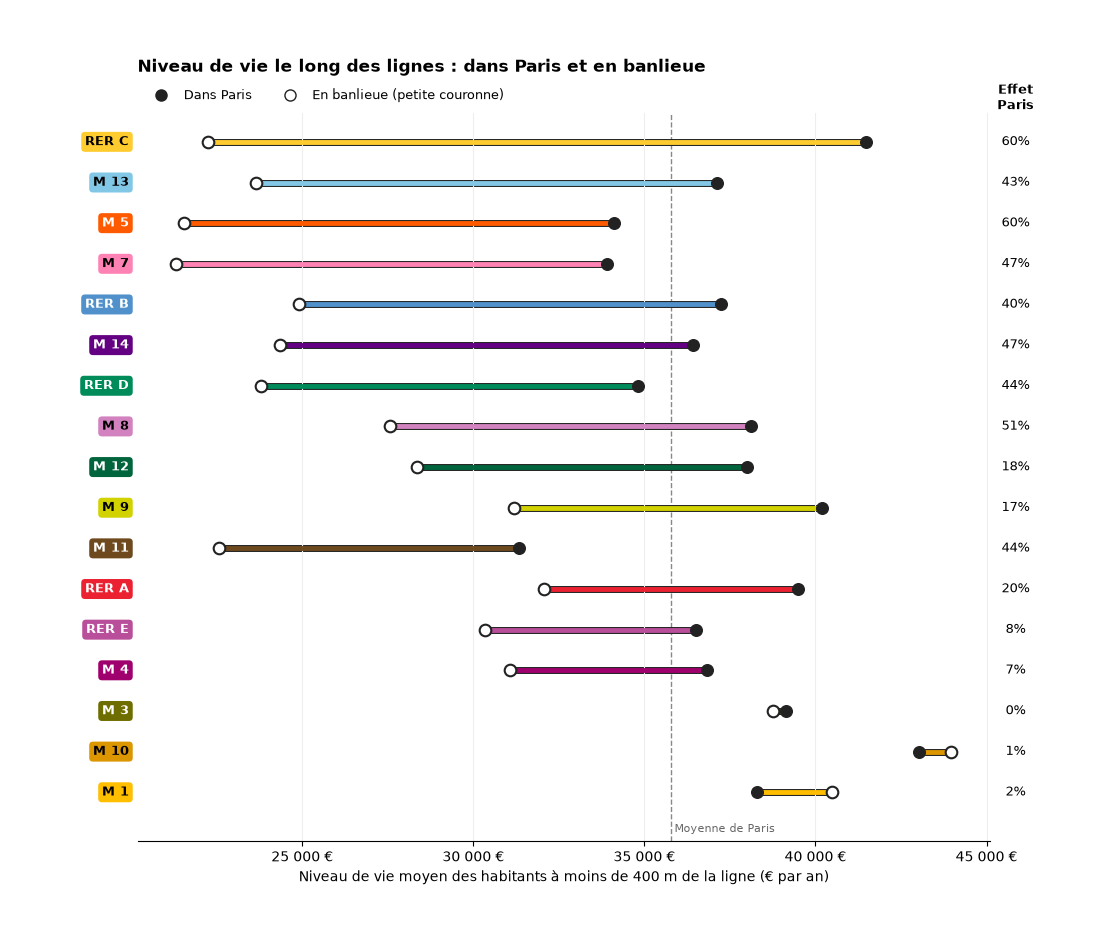

In [ ]:
ax = generer_halteres_paris_banlieue(df_heterogeneite, nv_paris)
enregistrer_graphique(ax, "Hétérogénéité : Paris et banlieue par ligne")
plt.show()

> **Lecture :** le long de la ligne 13, les habitants des tronçons situés dans Paris ont un niveau de vie moyen de 37 100 € par an, contre 23 700 € pour ceux des tronçons de banlieue, soit 36 % de moins. Sur la ligne 1, c'est l'inverse : la banlieue (40 500 €) est plus riche que Paris (38 300 €), et 54 % de ses habitants de banlieue vivent dans une commune plus riche que Paris, comme Neuilly-sur-Seine.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; lignes 2, 6, 3B et 7B exclues (entièrement dans Paris).* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Les banlieues plus riches que Paris

En vert, les communes de petite couronne dont le niveau de vie moyen dépasse celui de Paris (plus le vert est foncé, plus elles sont riches) ; les lignes de métro et de RER par-dessus.

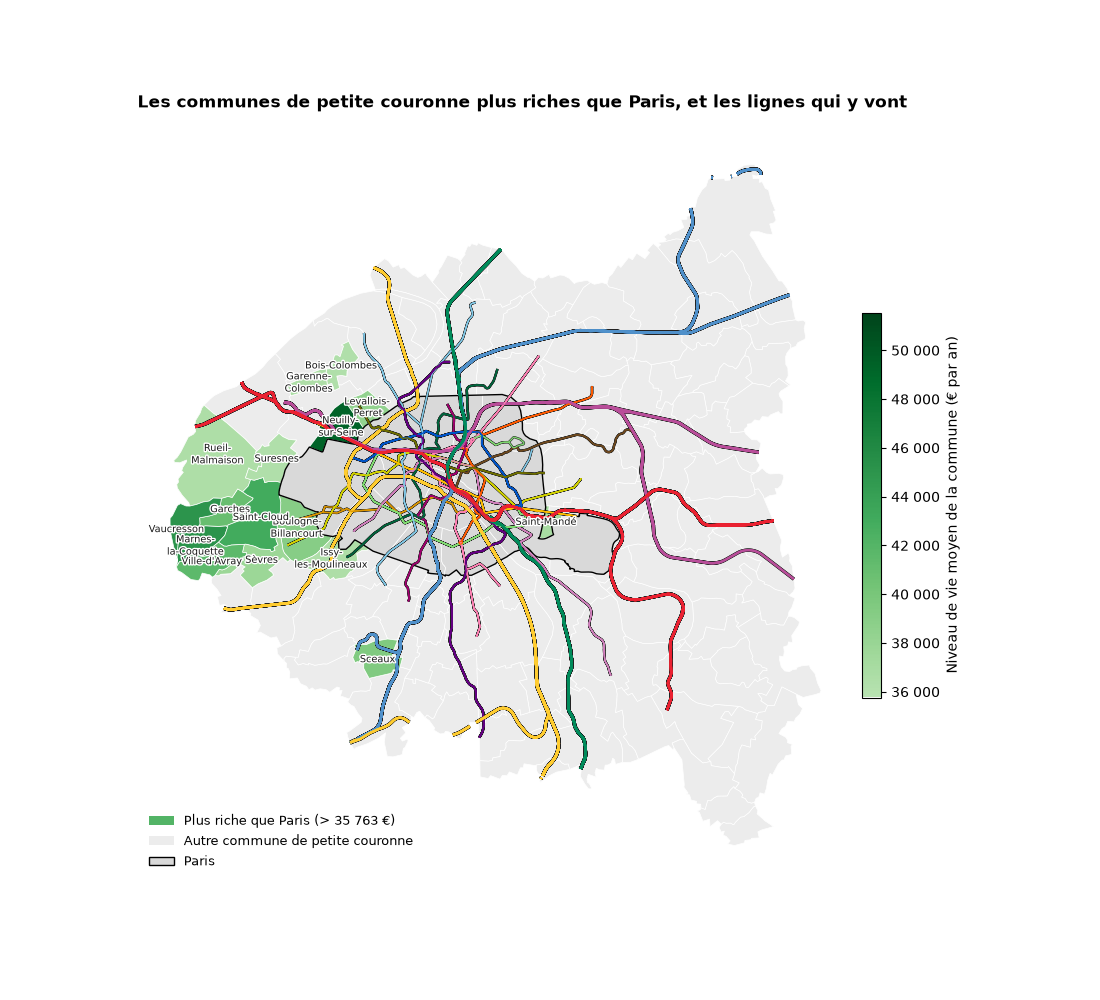

In [ ]:
ax = generer_carte_communes_riches(gpd_communes, gpd_zones, nv_paris, gpd_idfm)
enregistrer_graphique(ax, "Communes plus riches que Paris")
plt.show()

> **Lecture :** Neuilly-sur-Seine, la commune la plus riche de la petite couronne, a un niveau de vie moyen de 49 300 € par an, 38 % de plus que Paris (35 800 €). Seize communes dépassent Paris : quinze dans les Hauts-de-Seine, surtout à l'ouest, et Saint-Mandé dans le Val-de-Marne ; aucune en Seine-Saint-Denis.
>
> *Champ : habitants de Paris et de la petite couronne.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

**Commentaire**  

### Limites

- **Centre de Paris** : peu d'habitants vivent près des stations, et les stations sont si proches que chacune ne récupère que quelques carreaux (248 habitants pour Concorde, contre 48 000 pour La Défense). Les valeurs par station y sont fragiles ; les barres des carreaux le sont moins.
- **Lignes à branches** (13, RER A et B) : la montagne ne suit que la branche la plus longue (Saint-Denis pour la 13, Cergy → Chessy pour le A, Saint-Rémy → Roissy pour le B). Le plan montre toutes les branches, mais seules les stations de la branche suivie y sont marquées.
- **Stations en limite de commune** : chaque station est rattachée à la commune qui contient son point. Château de Vincennes tombe ainsi dans le 12e arrondissement (le bois de Vincennes fait partie de Paris).
- **Aéroport CDG** (RER B) : aucun habitant à moins de 1,5 km, donc pas de valeur pour ces deux stations. Et plus généralement : un carré sans habitant (la Seine, les parcs, les zones d'activité) n'apparaît pas du tout : ce sont les trous des montagnes.
- **RER dans Paris** : chaque habitant n'est rattaché qu'à sa station la plus proche, métro compris. Les gares du RER dans Paris (Auber, Châtelet - Les Halles…) ont donc très peu d'habitants rattachés : ils le sont aux stations de métro voisines.
